In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# La informalidad de los micronegocios

La Encuesta de Micronegocios (EMICRON) estudia los negocios de hasta 9 personas ocupadas de los patrones y los
trabajadores por cuenta propia que encuentra la GEIH. Tres de sus preguntas miden la informalidad empresarial: si el
negocio tiene RUT, si está registrado en una Cámara de Comercio y si el propietario aporta a salud y pensión.
Este ejemplo usa 2019–2024, los años con cobertura nacional.

In [2]:
import dane_data as dd

emi = dd.emicron.load(range(2019, 2025))
serie = dd.emicron.indicadores(emi)
serie[["anio", "micronegocios", "personal_ocupado", "pct_rut", "pct_camara_comercio",
       "pct_salud_pension"]].round(1)

,anio,micronegocios,personal_ocupado,pct_rut,pct_camara_comercio,pct_salud_pension
0,2019,5215035.0,7296699.0,23.1,11.2,7.4
1,2020,4819329.0,6397340.3,22.6,10.6,7.2
2,2021,4921210.0,6542110.7,21.5,10.5,7.0
3,2022,5150956.3,6887313.9,22.5,10.8,8.2
4,2023,5188402.4,6748263.3,23.8,10.5,9.4
5,2024,5297251.6,6879489.3,22.4,10.3,9.2


## Casi ocho de cada diez, sin RUT

Entre 2019 y 2024 la informalidad de los micronegocios casi no se movió: entre 21 % y 24 % tenía RUT y entre 10 % y
11 % estaba registrado en una Cámara de Comercio. Lo único que sube es el aporte del propietario a salud y pensión,
de 7,4 % en 2019 a 9,2 % en 2024. La actividad pesa mucho: en el comercio, un tercio tiene RUT; en la agricultura,
menos de 5 %.

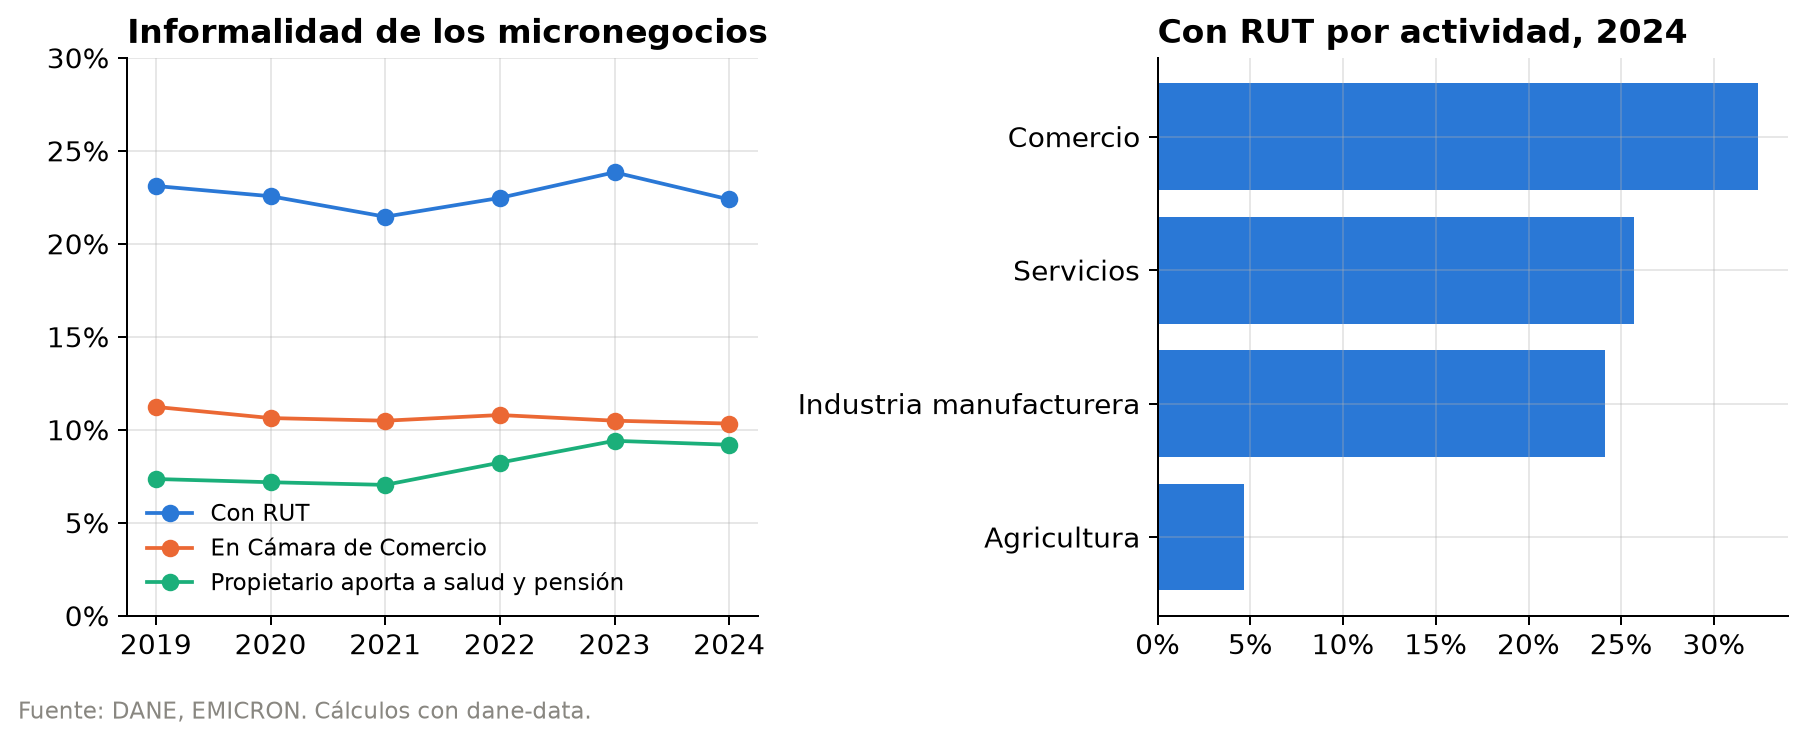

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for col, nombre in [("pct_rut", "Con RUT"), ("pct_camara_comercio", "En Cámara de Comercio"),
                    ("pct_salud_pension", "Propietario aporta a salud y pensión")]:
    axes[0].plot(serie["anio"], serie[col], marker="o", label=nombre)
axes[0].set_title("Informalidad de los micronegocios")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_ylim(0, 30)
axes[0].legend(fontsize=9)
por_actividad = dd.emicron.indicadores(emi[emi.anio == 2024], por="actividad")
por_actividad = por_actividad[por_actividad["actividad"] != "No informa"].sort_values("pct_rut")
axes[1].barh(por_actividad["actividad"].astype(str).str.replace(", ganadería, caza, silvicultura y pesca", ""),
             por_actividad["pct_rut"], color="#2a78d6")
axes[1].set_title("Con RUT por actividad, 2024")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.text(0, -0.04, "Fuente: DANE, EMICRON. Cálculos con dane-data.", fontsize=9, color="#898781")
fig.tight_layout()

## Muy distinta entre ciudades

En las cabeceras municipales 30 % de los micronegocios tiene RUT; en los centros poblados y el campo, 6 %. Entre las
24 ciudades va de 6 % en Sincelejo a 60 % en San Andrés, con Manizales y Tunja también por encima de 55 %.

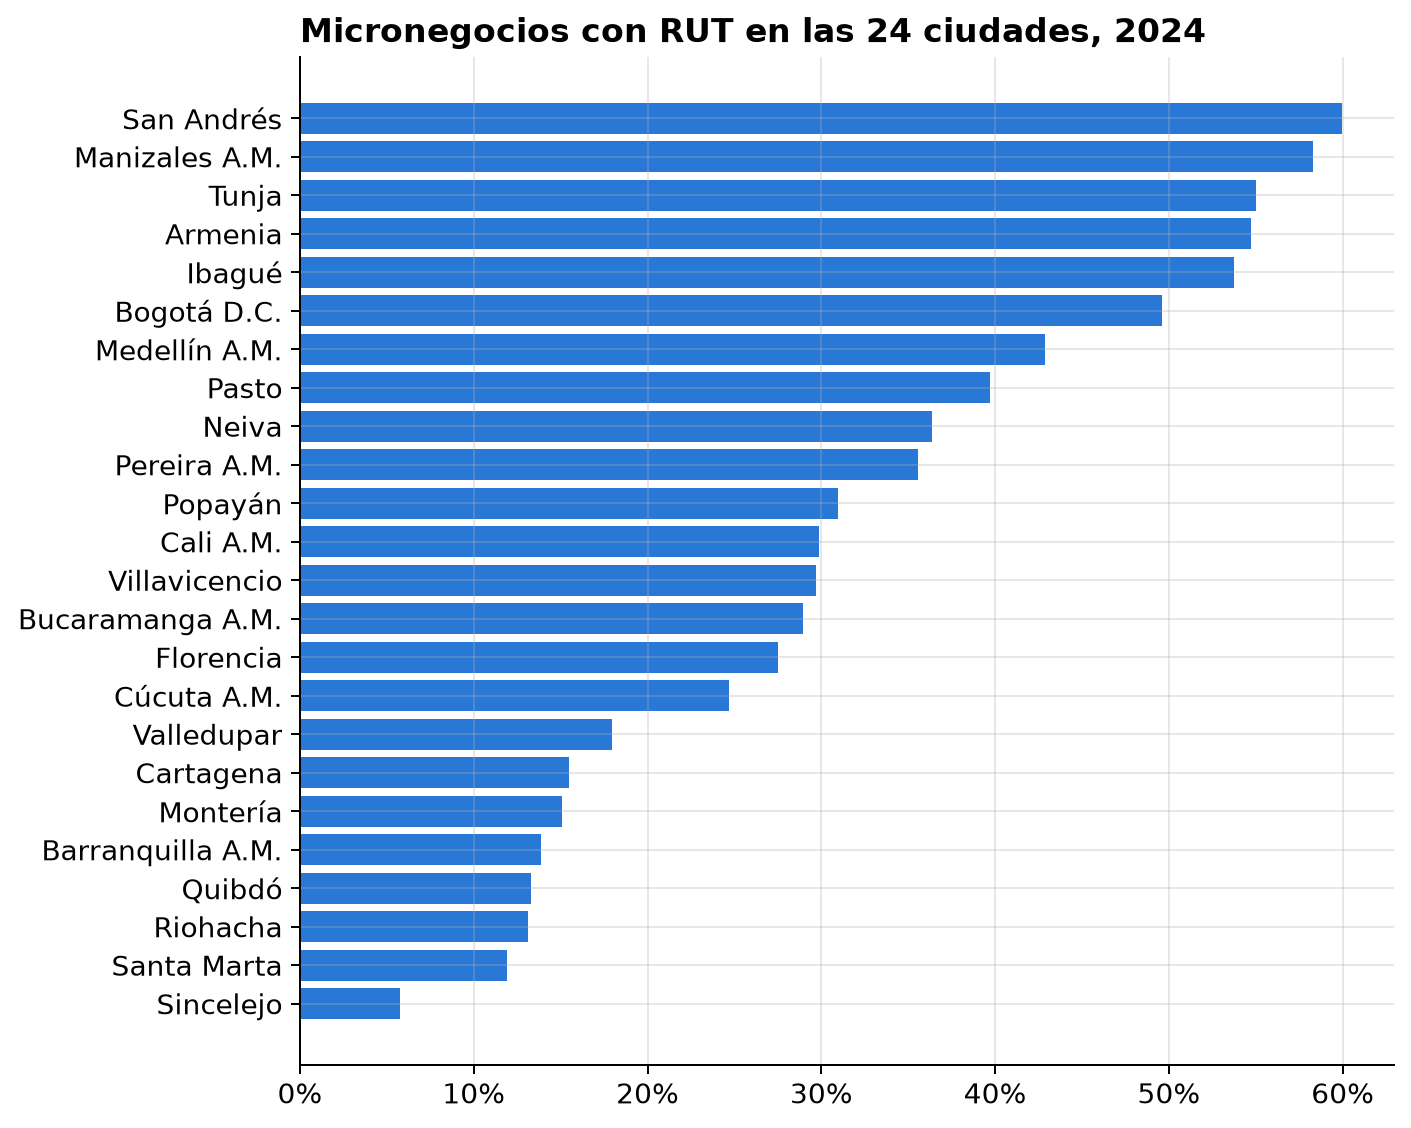

In [4]:
ciudades = dd.emicron.indicadores(emi[emi.anio == 2024], por="ciudad").sort_values("pct_rut")

fig, ax = plt.subplots(figsize=(8, 6.4))
ax.barh(ciudades["ciudad"].astype(str), ciudades["pct_rut"], color="#2a78d6")
ax.set_title("Micronegocios con RUT en las 24 ciudades, 2024")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.tight_layout()

## Con RUT, más valor agregado por persona

El DANE no publica este cruce, pero se arma con las mismas definiciones: {dd}`emicron.indicadores()` agrupado por
`rut`. Los montos están en miles de pesos corrientes del año.

In [5]:
productividad = dd.emicron.indicadores(emi[emi.anio == 2024], por="rut")
productividad["va_por_persona"] = productividad["valor_agregado"] / productividad["personal_ocupado"]
productividad[["rut", "micronegocios", "personal_ocupado", "va_por_persona", "coeficiente_tecnico"]].round(1)

,rut,micronegocios,personal_ocupado,va_por_persona,coeficiente_tecnico
0,False,4111274.1,4913716.1,9387.4,51.1
1,True,1185977.5,1965773.2,20668.0,58.0


En 2024, el valor agregado por persona ocupada de los micronegocios con RUT fue de unos 20,7 millones de pesos al
año, más del doble que el de los que no lo tienen (9,4 millones). Es una asociación, no un efecto: los que tienen RUT
son más grandes, están más en el comercio y en las ciudades.

```{seealso}
{doc}`../guia/emicron` explica las variables, el factor de expansión y lo que cambia con los años, y
{doc}`../guia/validacion` cómo se comparan las cifras con los anexos del DANE.
```